In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("../results/models", exist_ok=True)
os.makedirs("../results/plots", exist_ok=True)

df = pd.read_csv("../data/Unicorn_Companies_cleaned.csv")

# Treat implausibly small Total Raised (< $5M) as missing
df.loc[df["Total Raised (M)"] < 5, "Total Raised (M)"] = np.nan

# Targets
df["log_val"] = np.log(df["Valuation"])

# Features
df["log_raised"] = np.log(df["Total Raised (M)"])
df["Company Age"] = 2026 - df["Founded Year"]
df["Raised per Investor"] = df["Total Raised (M)"] / df["Investors Count"]
df["Is US"] = (df["Country"] == "United States").astype(int)

# Keep top 5 countries, group the rest, then one-hot encode
top_c = df["Country"].value_counts().head(5).index
df["Country Group"] = df["Country"].where(df["Country"].isin(top_c), "Other")

num_feats = ["log_raised", "Investors Count", "Deal Terms", "Founded Year",
             "Years to Unicorn", "Join Year", "Raised per Investor", "Is US"]
X = pd.concat([
    df[num_feats],
    pd.get_dummies(df["Industry"], prefix="ind"),
    pd.get_dummies(df["Country Group"], prefix="cty"),
], axis=1).astype(float)

print("Feature matrix:", X.shape)
print("Missing per numeric feature:")
print(X[num_feats].isnull().sum()[lambda s: s > 0])
print("\nExited:", df["Exited"].sum(), "of", len(df))

Feature matrix: (1037, 29)
Missing per numeric feature:
log_raised             32
Investors Count         1
Deal Terms             29
Founded Year           44
Years to Unicorn       44
Raised per Investor    33
dtype: int64

Exited: 49 of 1037


In [2]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error

y = df["log_val"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)),
    "XGBoost": make_pipeline(SimpleImputer(strategy="median"),
                             XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                          subsample=0.8, colsample_bytree=0.8, random_state=42)),
}

kf = KFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    cv = cross_validate(m, X_tr, y_tr, cv=kf, scoring=("r2", "neg_root_mean_squared_error"))
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    rows.append({"model": name,
                 "CV R2": round(cv["test_r2"].mean(), 3), "CV R2 std": round(cv["test_r2"].std(), 3),
                 "CV RMSE": round(-cv["test_neg_root_mean_squared_error"].mean(), 3),
                 "Test R2": round(r2_score(y_te, pred), 3),
                 "Test RMSE": round(np.sqrt(mean_squared_error(y_te, pred)), 3)})
    joblib.dump(m, f"../results/models/reg_{name.lower().replace(' ', '_')}.joblib")

res = pd.DataFrame(rows).set_index("model")
print(res)

                   CV R2  CV R2 std  CV RMSE  Test R2  Test RMSE
model                                                           
Linear Regression  0.364      0.090    0.613    0.439      0.590
Random Forest      0.451      0.096    0.568    0.504      0.555
XGBoost            0.468      0.092    0.559    0.486      0.565


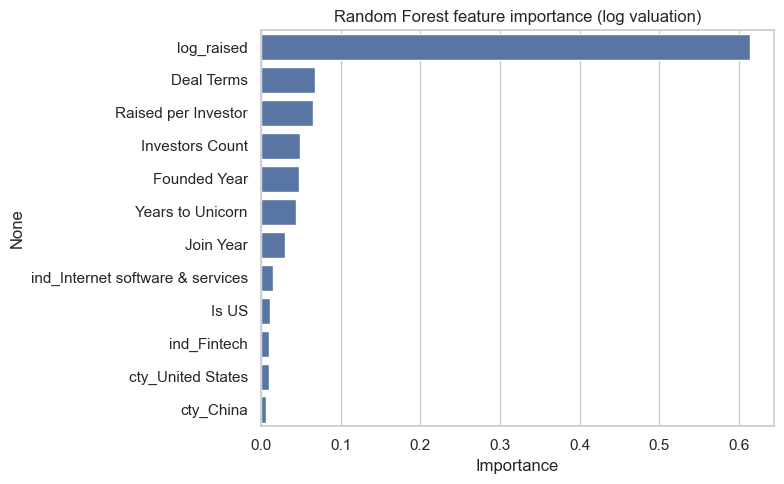

log_raised                          0.613
Deal Terms                          0.068
Raised per Investor                 0.065
Investors Count                     0.049
Founded Year                        0.048
Years to Unicorn                    0.044
Join Year                           0.030
ind_Internet software & services    0.015
Is US                               0.012
ind_Fintech                         0.010
cty_United States                   0.010
cty_China                           0.006
dtype: float64


In [3]:
rf = models["Random Forest"]
imp = pd.Series(rf[-1].feature_importances_, index=X.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#4C72B0")
plt.title("Random Forest feature importance (log valuation)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../results/plots/04_feature_importance.png", dpi=150)
plt.show()
print(imp.round(3))


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, f1_score)

# Add valuation features (valid here: the target is exit, not valuation)
Xc = X.copy()
Xc["log_val"] = df["log_val"]
yc = df["Exited"]

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)
pos_w = (yc_tr == 0).sum() / (yc_tr == 1).sum()

clfs = {
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                          class_weight="balanced", random_state=42, n_jobs=-1)),
    "XGBoost": make_pipeline(SimpleImputer(strategy="median"),
                             XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                           subsample=0.8, colsample_bytree=0.8,
                                           scale_pos_weight=pos_w, random_state=42)),
}

skf = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in clfs.items():
    cv = cross_validate(m, Xc_tr, yc_tr, cv=skf, scoring=("roc_auc", "average_precision", "f1"))
    m.fit(Xc_tr, yc_tr)
    proba = m.predict_proba(Xc_te)[:, 1]
    pred = m.predict(Xc_te)
    rows.append({"model": name,
                 "CV AUC": round(cv["test_roc_auc"].mean(), 3),
                 "CV AP": round(cv["test_average_precision"].mean(), 3),
                 "CV F1": round(cv["test_f1"].mean(), 3),
                 "Test AUC": round(roc_auc_score(yc_te, proba), 3),
                 "Test F1": round(f1_score(yc_te, pred), 3)})
    joblib.dump(m, f"../results/models/clf_{name.lower().replace(' ', '_')}.joblib")

print(pd.DataFrame(rows).set_index("model"))
print("\nBaseline (always predict 'not exited') accuracy: %.3f" % (1 - yc.mean()))

                     CV AUC  CV AP  CV F1  Test AUC  Test F1
model                                                       
Logistic Regression   0.749  0.244  0.221     0.854    0.254
Random Forest         0.829  0.286  0.081     0.879    0.250
XGBoost               0.786  0.233  0.228     0.865    0.296

Baseline (always predict 'not exited') accuracy: 0.953


Best threshold (from CV, training data only): 0.366  (CV F1 = 0.326)

Test set at tuned threshold:
              precision    recall  f1-score   support

     Private       0.97      0.92      0.95       198
      Exited       0.24      0.50      0.32        10

    accuracy                           0.90       208
   macro avg       0.61      0.71      0.63       208
weighted avg       0.94      0.90      0.92       208



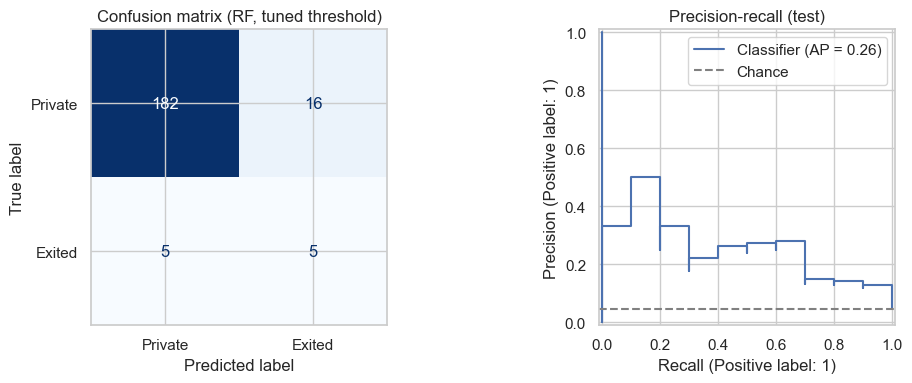

In [5]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

best = clfs["Random Forest"]
oof = cross_val_predict(best, Xc_tr, yc_tr, cv=skf, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(yc_tr, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
t = thr[np.argmax(f1s[:-1])]
print("Best threshold (from CV, training data only): %.3f  (CV F1 = %.3f)" % (t, f1s[:-1].max()))

best.fit(Xc_tr, yc_tr)
proba = best.predict_proba(Xc_te)[:, 1]
pred = (proba >= t).astype(int)
print("\nTest set at tuned threshold:")
print(classification_report(yc_te, pred, target_names=["Private", "Exited"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(yc_te, pred), display_labels=["Private", "Exited"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (RF, tuned threshold)")
PrecisionRecallDisplay.from_predictions(yc_te, proba, ax=axes[1])
axes[1].axhline(yc.mean(), color="gray", ls="--", label="Chance")
axes[1].legend()
axes[1].set_title("Precision-recall (test)")
plt.tight_layout()
plt.savefig("../results/plots/04_classifier_results.png", dpi=150)
plt.show()

In [6]:
print("KEY FINDINGS (Notebook 4)")
print("- Valuation (log) regression, 5-fold CV R2: Linear 0.36, RF 0.45, XGBoost 0.47 (RF vs XGB within noise)")
print("- Total Raised = 61% of RF importance; industry and country nearly irrelevant")
print("- Exit classifier (49 exits / 1037): CV AUC 0.75-0.83, CV AP 0.23-0.29 vs chance 0.047")
print("- RF at CV-tuned threshold 0.366: test recall 0.50, precision 0.24, F1 0.32 (only 10 test exits)")
print("- Accuracy is misleading: 'never exits' baseline = 95.3%")

KEY FINDINGS (Notebook 4)
- Valuation (log) regression, 5-fold CV R2: Linear 0.36, RF 0.45, XGBoost 0.47 (RF vs XGB within noise)
- Total Raised = 61% of RF importance; industry and country nearly irrelevant
- Exit classifier (49 exits / 1037): CV AUC 0.75-0.83, CV AP 0.23-0.29 vs chance 0.047
- RF at CV-tuned threshold 0.366: test recall 0.50, precision 0.24, F1 0.32 (only 10 test exits)
- Accuracy is misleading: 'never exits' baseline = 95.3%
